In [5]:
import os
import numpy as np 
import pandas as pd
from tqdm import tqdm 
from muq import MuQ
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.manifold import TSNE
from sklearn.neighbors import NearestNeighbors
import matplotlib.pyplot as plt
from typing import Dict, List, Tuple, Optional
import json


/home/waarab/torchtest/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2025-12-12 14:54:07.315725: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [62]:
def get_path(path):
    df = pd.read_csv("/home/waarab/ia/free-gen-playlist/mtg-jamendo-dataset/data/splits/"+path,
        sep="\t",
        engine="python",
        on_bad_lines="skip"  # or "warn"
    )
    
    return df


In [3]:
#Extract all paths with only one genre 



#Split 0
df = get_path("split-0/autotagging_genre-train.tsv")
one_tag_rows_genre_0= df[df["TAGS"].apply(lambda t: isinstance(t, str) and len(t.split()) == 1)]
genre_paths = one_tag_rows_genre_0["PATH"].tolist()


#split 1

df = get_path("split-1/autotagging_genre-train.tsv")
one_tag_rows_genre_1 = df[df["TAGS"].apply(lambda t: isinstance(t, str) and len(t.split()) == 1)]
genre_paths += one_tag_rows_genre_1["PATH"].tolist()

#split 2 

df = get_path("split-2/autotagging_genre-train.tsv")
one_tag_rows_genre_2 = df[df["TAGS"].apply(lambda t: isinstance(t, str) and len(t.split()) == 1)]
genre_paths += one_tag_rows_genre_2["PATH"].tolist()



print(len(genre_paths))



21757


In [4]:
df = get_path("split-0/autotagging_instrument-train.tsv")

# Keep rows where there is exactly ONE tag
one_tag_rows_instrument_0 = df[df["TAGS"].apply(lambda t: isinstance(t, str) and len(t.split()) == 1)]

# Keep only rows whose PATH is in genre_paths
one_tag_rows_instrument_0 = one_tag_rows_instrument_0[one_tag_rows_instrument_0["PATH"].isin(genre_paths)]

# Extract the paths
instrument_path = one_tag_rows_instrument_0["PATH"].tolist()

df = get_path("split-1/autotagging_instrument-train.tsv")

# Keep rows where there is exactly ONE tag
one_tag_rows_instrument_1 = df[df["TAGS"].apply(lambda t: isinstance(t, str) and len(t.split()) == 1)]

# Keep only rows whose PATH is in genre_paths
one_tag_rows_instrument_1 = one_tag_rows_instrument_1[one_tag_rows_instrument_1["PATH"].isin(genre_paths)]

# Extract the paths
instrument_path += one_tag_rows_instrument_1["PATH"].tolist()


df = get_path("split-2/autotagging_instrument-train.tsv")

# Keep rows where there is exactly ONE tag
one_tag_rows_instrument_2 = df[df["TAGS"].apply(lambda t: isinstance(t, str) and len(t.split()) == 1)]

# Keep only rows whose PATH is in genre_paths
one_tag_rows_instrument_2 = one_tag_rows_instrument_2[one_tag_rows_instrument_2["PATH"].isin(genre_paths)]

# Extract the paths
instrument_path += one_tag_rows_instrument_2["PATH"].tolist()

print(len(instrument_path))


4780


In [5]:
df = get_path("split-0/autotagging_moodtheme-train.tsv")

# Keep rows where there is exactly ONE tag
one_tag_rows_mood = df[df["TAGS"].apply(lambda t: isinstance(t, str) and len(t.split()) == 1)]

# Keep only rows whose PATH is in genre_paths + instrument_path
one_tag_rows_mood_0 = one_tag_rows_mood[one_tag_rows_mood["PATH"].isin(instrument_path)]

# Extract the paths
paths = one_tag_rows_mood_0["PATH"].tolist()

df = get_path("split-1/autotagging_moodtheme-train.tsv")

# Keep rows where there is exactly ONE tag
one_tag_rows_mood = df[df["TAGS"].apply(lambda t: isinstance(t, str) and len(t.split()) == 1)]

# Keep only rows whose PATH is in genre_paths
one_tag_rows_mood_1 = one_tag_rows_mood[one_tag_rows_mood["PATH"].isin(instrument_path)]

# Extract the paths
paths += one_tag_rows_mood_1["PATH"].tolist()


df = get_path("split-2/autotagging_moodtheme-train.tsv")

# Keep rows where there is exactly ONE tag
one_tag_rows_mood = df[df["TAGS"].apply(lambda t: isinstance(t, str) and len(t.split()) == 1)]

# Keep only rows whose PATH is in genre_paths
one_tag_rows_mood_2 = one_tag_rows_mood[one_tag_rows_mood["PATH"].isin(instrument_path)]

# Extract the paths
paths += one_tag_rows_mood_2["PATH"].tolist()

print(len(paths))


1104


In [6]:
from itertools import chain

dfs = [
    one_tag_rows_genre_0,
    one_tag_rows_genre_1,
    one_tag_rows_genre_2,
    
    one_tag_rows_instrument_0,
    one_tag_rows_instrument_1,
    one_tag_rows_instrument_2,
    
    one_tag_rows_mood_0,
    one_tag_rows_mood_1,
    one_tag_rows_mood_2
]

genre_tags = [ df[df["PATH"].isin(paths)]["TAGS"].tolist() for df in dfs[:3] ]

instrument_tags = [ df[df["PATH"].isin(paths)]["TAGS"].tolist() for df in dfs[3:6] ]

mood_tags = [ df[df["PATH"].isin(paths)]["TAGS"].tolist() for df in dfs[6:9] ]

genre_tags = list(chain.from_iterable(genre_tags))
instrument_tags = list(chain.from_iterable(instrument_tags))
mood_tags = list(chain.from_iterable(mood_tags))

mood_tags = [tag.split('---')[-1] for tag in mood_tags]
genre_tags = [tag.split('---')[-1] for tag in genre_tags]
instrument_tags = [tag.split('---')[-1] for tag in instrument_tags]

print(len(genre_tags), len(instrument_tags), len(mood_tags))

1104 1104 1104


In [7]:
# Extract embeddings
from embedding_extraction import extract_embedding
import torch
import numpy as np
import pandas as pd
import os

data_dir = '/home/waarab/ia/free-gen-playlist/data/jamendo'

embeddings = []
filenames = []
filegenres = []
fileinstruments = []
fileemotions = []

# Assure-toi que paths correspond bien aux fichiers .low.mp3
paths = [path.split('.')[0]+".low.mp3" for path in paths]

for i, (p, genre, instrument, mood) in enumerate(zip(paths, genre_tags, instrument_tags, mood_tags), 1):    
    full_path = os.path.join(data_dir, p)
    
    # Extraire embedding
    embedding = extract_embedding(full_path)  # doit renvoyer un np.array
    
    embeddings.append(embedding)
    filenames.append(p)
    filegenres.append(genre)
    fileinstruments.append(instrument)
    fileemotions.append(mood)
    

    print(f"✅ fichiers traités : {p}")
    
    # Libérer GPU si extract_embedding utilise torch
    torch.cuda.empty_cache()

# Convertir en numpy array
embeddings = np.array(embeddings)

# Créer DataFrame
df = pd.DataFrame(embeddings)
df['filename'] = filenames
df['genre'] = filegenres
df['instrument'] = fileinstruments
df['emotion'] = fileemotions

df.to_csv("muq_embedding_jamendo_multiclass.csv", index=False)

print("✅ Extraction terminée !")
print("Dimensions embeddings :", embeddings.shape)



/home/waarab/torchtest/lib/python3.12/site-packages/torch/nn/utils/weight_norm.py:143: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)


✅ fichiers traités : 13/14013.low.mp3
✅ fichiers traités : 14/14014.low.mp3
✅ fichiers traités : 15/14015.low.mp3
✅ fichiers traités : 16/14016.low.mp3
✅ fichiers traités : 17/14017.low.mp3
✅ fichiers traités : 18/14018.low.mp3
✅ fichiers traités : 20/14020.low.mp3
✅ fichiers traités : 21/14021.low.mp3
✅ fichiers traités : 22/14022.low.mp3
✅ fichiers traités : 23/14023.low.mp3
✅ fichiers traités : 24/14024.low.mp3
✅ fichiers traités : 25/14025.low.mp3
✅ fichiers traités : 27/14027.low.mp3
✅ fichiers traités : 28/14028.low.mp3
✅ fichiers traités : 56/78956.low.mp3
✅ fichiers traités : 00/95400.low.mp3
✅ fichiers traités : 38/95538.low.mp3
✅ fichiers traités : 65/114765.low.mp3
✅ fichiers traités : 72/114772.low.mp3
✅ fichiers traités : 73/114773.low.mp3
✅ fichiers traités : 80/114780.low.mp3
✅ fichiers traités : 81/114781.low.mp3
✅ fichiers traités : 94/114794.low.mp3
✅ fichiers traités : 23/175423.low.mp3
✅ fichiers traités : 19/196219.low.mp3
✅ fichiers traités : 21/196221.low.mp3
✅ f

✅ fichiers traités : 44/1162944.low.mp3
✅ fichiers traités : 45/1162945.low.mp3
✅ fichiers traités : 46/1162946.low.mp3
✅ fichiers traités : 58/1162958.low.mp3
✅ fichiers traités : 88/1168388.low.mp3
✅ fichiers traités : 16/1171016.low.mp3
✅ fichiers traités : 40/1173740.low.mp3
✅ fichiers traités : 65/1174465.low.mp3
✅ fichiers traités : 66/1174466.low.mp3
✅ fichiers traités : 67/1174467.low.mp3
✅ fichiers traités : 88/1179888.low.mp3
✅ fichiers traités : 31/1197331.low.mp3
✅ fichiers traités : 90/1197390.low.mp3
✅ fichiers traités : 75/1203475.low.mp3
✅ fichiers traités : 76/1203476.low.mp3
✅ fichiers traités : 78/1203478.low.mp3
✅ fichiers traités : 88/1203488.low.mp3
✅ fichiers traités : 42/1208442.low.mp3
✅ fichiers traités : 49/1208449.low.mp3
✅ fichiers traités : 43/1208843.low.mp3
✅ fichiers traités : 21/1218921.low.mp3
✅ fichiers traités : 65/1230765.low.mp3
✅ fichiers traités : 69/1230769.low.mp3
✅ fichiers traités : 70/1230770.low.mp3
✅ fichiers traités : 71/1230771.low.mp3


✅ fichiers traités : 27/663127.low.mp3
✅ fichiers traités : 28/663128.low.mp3
✅ fichiers traités : 29/663129.low.mp3
✅ fichiers traités : 30/663130.low.mp3
✅ fichiers traités : 31/663131.low.mp3
✅ fichiers traités : 32/663132.low.mp3
✅ fichiers traités : 33/663133.low.mp3
✅ fichiers traités : 34/663134.low.mp3
✅ fichiers traités : 37/663137.low.mp3
✅ fichiers traités : 65/743965.low.mp3
✅ fichiers traités : 66/743966.low.mp3
✅ fichiers traités : 24/779224.low.mp3
✅ fichiers traités : 17/784717.low.mp3
✅ fichiers traités : 60/830860.low.mp3
✅ fichiers traités : 66/830866.low.mp3
✅ fichiers traités : 69/830869.low.mp3
✅ fichiers traités : 70/830870.low.mp3
✅ fichiers traités : 74/830874.low.mp3
✅ fichiers traités : 93/830893.low.mp3
✅ fichiers traités : 27/857627.low.mp3
✅ fichiers traités : 28/857628.low.mp3
✅ fichiers traités : 31/857631.low.mp3
✅ fichiers traités : 33/857633.low.mp3
✅ fichiers traités : 35/857635.low.mp3
✅ fichiers traités : 36/857636.low.mp3
✅ fichiers traités : 23/8

✅ fichiers traités : 69/1230769.low.mp3
✅ fichiers traités : 70/1230770.low.mp3
✅ fichiers traités : 71/1230771.low.mp3
✅ fichiers traités : 73/1230773.low.mp3
✅ fichiers traités : 75/1230775.low.mp3
✅ fichiers traités : 76/1230776.low.mp3
✅ fichiers traités : 79/1230779.low.mp3
✅ fichiers traités : 80/1230780.low.mp3
✅ fichiers traités : 05/1230805.low.mp3
✅ fichiers traités : 06/1230806.low.mp3
✅ fichiers traités : 87/1230987.low.mp3
✅ fichiers traités : 42/1231542.low.mp3
✅ fichiers traités : 48/1232048.low.mp3
✅ fichiers traités : 49/1232049.low.mp3
✅ fichiers traités : 50/1232050.low.mp3
✅ fichiers traités : 51/1232051.low.mp3
✅ fichiers traités : 52/1232052.low.mp3
✅ fichiers traités : 41/1254441.low.mp3
✅ fichiers traités : 42/1254442.low.mp3
✅ fichiers traités : 43/1254443.low.mp3
✅ fichiers traités : 44/1254444.low.mp3
✅ fichiers traités : 45/1254445.low.mp3
✅ fichiers traités : 46/1254446.low.mp3
✅ fichiers traités : 47/1254447.low.mp3
✅ fichiers traités : 48/1254448.low.mp3


✅ fichiers traités : 29/662429.low.mp3
✅ fichiers traités : 30/662430.low.mp3
✅ fichiers traités : 40/662440.low.mp3
✅ fichiers traités : 41/662441.low.mp3
✅ fichiers traités : 42/662442.low.mp3
✅ fichiers traités : 44/662444.low.mp3
✅ fichiers traités : 93/663093.low.mp3
✅ fichiers traités : 94/663094.low.mp3
✅ fichiers traités : 95/663095.low.mp3
✅ fichiers traités : 96/663096.low.mp3
✅ fichiers traités : 27/663127.low.mp3
✅ fichiers traités : 28/663128.low.mp3
✅ fichiers traités : 29/663129.low.mp3
✅ fichiers traités : 30/663130.low.mp3
✅ fichiers traités : 31/663131.low.mp3
✅ fichiers traités : 32/663132.low.mp3
✅ fichiers traités : 33/663133.low.mp3
✅ fichiers traités : 34/663134.low.mp3
✅ fichiers traités : 37/663137.low.mp3
✅ fichiers traités : 89/674289.low.mp3
✅ fichiers traités : 09/674309.low.mp3
✅ fichiers traités : 65/743965.low.mp3
✅ fichiers traités : 66/743966.low.mp3
✅ fichiers traités : 91/770491.low.mp3
✅ fichiers traités : 24/779224.low.mp3
✅ fichiers traités : 17/7

✅ fichiers traités : 45/1254445.low.mp3
✅ fichiers traités : 46/1254446.low.mp3
✅ fichiers traités : 47/1254447.low.mp3
✅ fichiers traités : 48/1254448.low.mp3
✅ fichiers traités : 49/1254449.low.mp3
✅ fichiers traités : 50/1254450.low.mp3
✅ fichiers traités : 51/1254451.low.mp3
✅ fichiers traités : 52/1254452.low.mp3
✅ fichiers traités : 53/1254453.low.mp3
✅ fichiers traités : 07/1268107.low.mp3
✅ fichiers traités : 08/1268108.low.mp3
✅ fichiers traités : 09/1268109.low.mp3
✅ fichiers traités : 10/1268110.low.mp3
✅ fichiers traités : 11/1268111.low.mp3
✅ fichiers traités : 12/1268112.low.mp3
✅ fichiers traités : 13/1268113.low.mp3
✅ fichiers traités : 14/1268114.low.mp3
✅ fichiers traités : 15/1268115.low.mp3
✅ fichiers traités : 16/1268116.low.mp3
✅ fichiers traités : 17/1268117.low.mp3
✅ fichiers traités : 18/1268118.low.mp3
✅ fichiers traités : 78/1277178.low.mp3
✅ fichiers traités : 80/1277180.low.mp3
✅ fichiers traités : 81/1277181.low.mp3
✅ fichiers traités : 82/1277182.low.mp3


In [25]:
import sys
sys.path.append("/home/waarab/ia/free-gen-playlist")
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt
import numpy as np
from Viz.tsne_vis import load_embeddings



Loaded embeddings shape: (1104, 1024)
t-SNE result shape: (1104, 2)
✅ t-SNE plot saved as tsne_muQ_embeddings_nsynth.png


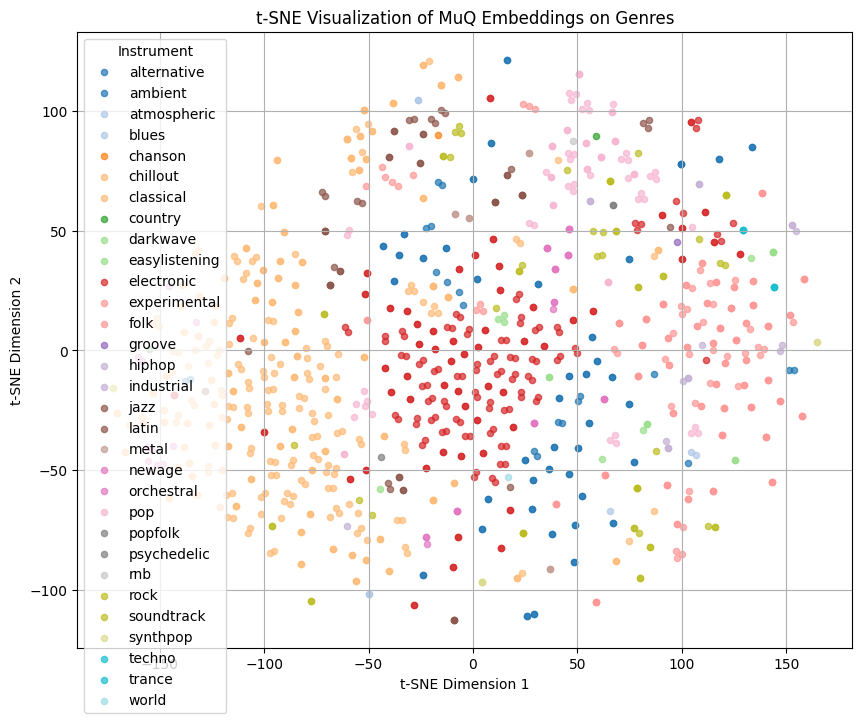

In [63]:
csv_path = "muq_embedding_jamendo_multiclass.csv"
data = pd.read_csv(csv_path)
instruments = data['genre']  #  the second last column is 'instrument'
filenames = data['filename']  #  the last column is 'filename'
data.drop(columns=['instrument', 'filename','genre','emotion'], inplace=True)
embeddings , instruments , filenames = data.to_numpy(), instruments.to_numpy(), filenames.to_numpy()
X_2d = TSNE(n_components=2, random_state=42).fit_transform(embeddings)
print("Loaded embeddings shape:", embeddings.shape)
print("t-SNE result shape:", X_2d.shape)
plt.figure(figsize=(10, 8))
# Obtenir la liste unique des instruments
unique_instruments = np.unique(instruments)
n_classes = len(unique_instruments)

cmap = plt.get_cmap("tab20")
colors = [cmap(i / n_classes) for i in range(n_classes)]
class_to_color = {cls: colors[i] for i, cls in enumerate(unique_instruments)}
# Plot instrument par instrument
for instrument in unique_instruments:
    idx = instruments == instrument
    plt.scatter(X_2d[idx, 0], X_2d[idx, 1], label=instrument, color=class_to_color[instrument], alpha=0.7, s=20)
plt.title("t-SNE Visualization of MuQ Embeddings on Genres")
plt.xlabel("t-SNE Dimension 1")
plt.ylabel("t-SNE Dimension 2")
plt.legend(title="Instrument")
plt.grid(True)
# Sauvegarde du graphique
plt.savefig("tsne_muQ_embeddings_jamendo_genres.png", dpi=300)
print("✅ t-SNE plot saved as tsne_muQ_embeddings_nsynth.png")

Loaded embeddings shape: (1104, 1024)
t-SNE result shape: (1104, 2)
✅ t-SNE plot saved as tsne_muQ_embeddings_nsynth.png


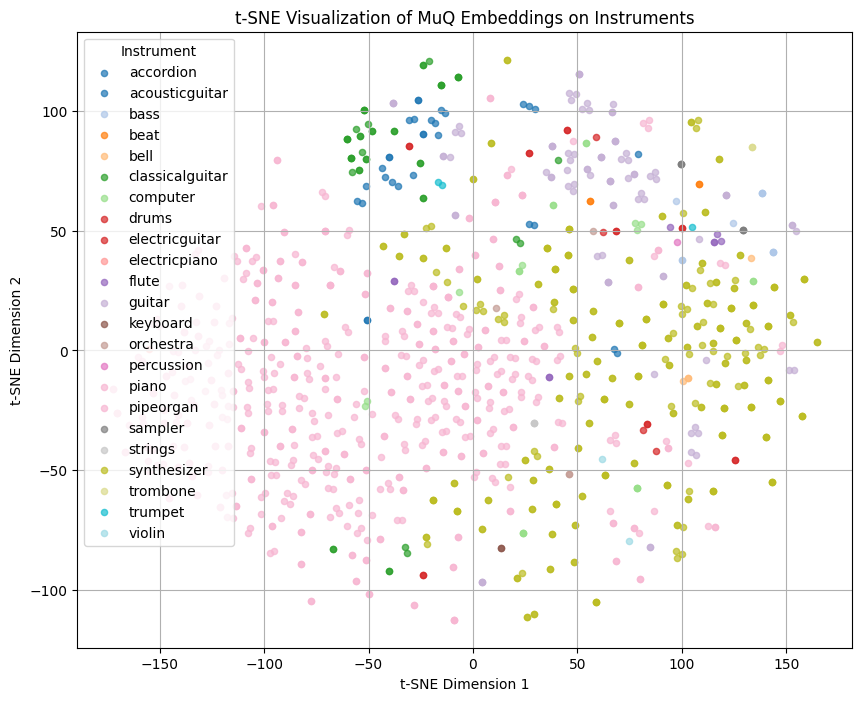

In [64]:


csv_path = "muq_embedding_jamendo_multiclass.csv"
data = pd.read_csv(csv_path)
instruments = data['instrument']  #  the second last column is 'instrument'
filenames = data['filename']  #  the last column is 'filename'
data.drop(columns=['instrument', 'filename','genre','emotion'], inplace=True)
embeddings , instruments , filenames = data.to_numpy(), instruments.to_numpy(), filenames.to_numpy()
X_2d = TSNE(n_components=2, random_state=42).fit_transform(embeddings)
print("Loaded embeddings shape:", embeddings.shape)
print("t-SNE result shape:", X_2d.shape)
plt.figure(figsize=(10, 8))
# Obtenir la liste unique des instruments
unique_instruments = np.unique(instruments)
n_classes = len(unique_instruments)

cmap = plt.get_cmap("tab20")
colors = [cmap(i / n_classes) for i in range(n_classes)]
class_to_color = {cls: colors[i] for i, cls in enumerate(unique_instruments)}
# Plot instrument par instrument
for instrument in unique_instruments:
    idx = instruments == instrument
    plt.scatter(X_2d[idx, 0], X_2d[idx, 1], label=instrument, color=class_to_color[instrument], alpha=0.7, s=20)
plt.title("t-SNE Visualization of MuQ Embeddings on Instruments")
plt.xlabel("t-SNE Dimension 1")
plt.ylabel("t-SNE Dimension 2")
plt.legend(title="Instrument")
plt.grid(True)
# Sauvegarde du graphique
plt.savefig("tsne_muQ_embeddings_jamendo_instruments.png", dpi=300)
print("✅ t-SNE plot saved as tsne_muQ_embeddings_nsynth.png")

Loaded embeddings shape: (1104, 1024)
t-SNE result shape: (1104, 2)
✅ t-SNE plot saved as tsne_muQ_embeddings_jamendo_emotions.png


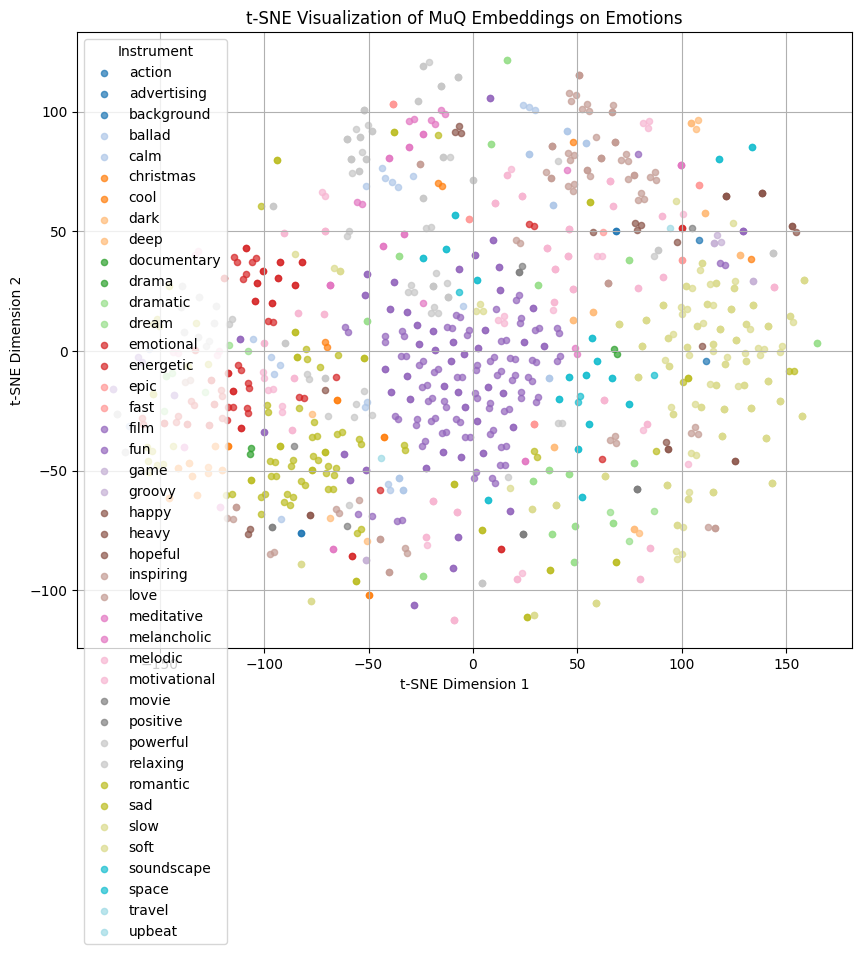

In [65]:
csv_path = "muq_embedding_jamendo_multiclass.csv"
data = pd.read_csv(csv_path)
instruments = data['emotion']  #  the second last column is emotion
filenames = data['filename']  #  the last column is 'filename'
data.drop(columns=['instrument', 'filename','genre','emotion'], inplace=True)
embeddings , instruments , filenames = data.to_numpy(), instruments.to_numpy(), filenames.to_numpy()
X_2d = TSNE(n_components=2, random_state=42).fit_transform(embeddings)
print("Loaded embeddings shape:", embeddings.shape)
print("t-SNE result shape:", X_2d.shape)
plt.figure(figsize=(10, 8))
# Obtenir la liste unique des instruments
unique_instruments = np.unique(instruments)
n_classes = len(unique_instruments)

cmap = plt.get_cmap("tab20")
colors = [cmap(i / n_classes) for i in range(n_classes)]
class_to_color = {cls: colors[i] for i, cls in enumerate(unique_instruments)}
# Plot instrument par instrument
for instrument in unique_instruments:
    idx = instruments == instrument
    plt.scatter(X_2d[idx, 0], X_2d[idx, 1], label=instrument, color=class_to_color[instrument], alpha=0.7, s=20)
plt.title("t-SNE Visualization of MuQ Embeddings on Emotions")
plt.xlabel("t-SNE Dimension 1")
plt.ylabel("t-SNE Dimension 2")
plt.legend(title="Instrument")
plt.grid(True)
# Sauvegarde du graphique
plt.savefig("tsne_muQ_embeddings_jamendo_emotions.png", dpi=300)
print("✅ t-SNE plot saved as tsne_muQ_embeddings_jamendo_emotions.png")

In [3]:
import pandas as pd
from collections import Counter

# Charger le CSV
csv_path = "muq_embedding_jamendo_multiclass.csv"
data = pd.read_csv(csv_path)

# Extraire les colonnes de tags
genre_tags = data['genre'].tolist()
instrument_tags = data['instrument'].tolist()
emotion_tags = data['emotion'].tolist()

# Compter les occurrences
genre_counts = Counter(genre_tags)
instrument_counts = Counter(instrument_tags)
emotion_counts = Counter(emotion_tags)

# Convertir en DataFrame pour lecture
df_genre = pd.DataFrame(genre_counts.items(), columns=['Genre', 'Count']).sort_values(by='Count', ascending=False)
df_instrument = pd.DataFrame(instrument_counts.items(), columns=['Instrument', 'Count']).sort_values(by='Count', ascending=False)
df_emotion = pd.DataFrame(emotion_counts.items(), columns=['Emotion', 'Count']).sort_values(by='Count', ascending=False)

# Afficher les résultats
print("=== Genres ===")
print(df_genre)

print("\n=== Instruments ===")
print(df_instrument)

print("\n=== Emotions / Mood ===")
print(df_emotion)


=== Genres ===
            Genre  Count
0       classical    334
5      electronic    211
18   experimental    148
1         ambient    101
11            pop     75
3            jazz     47
2      soundtrack     47
10         newage     35
8          hiphop     16
14           folk     14
4   easylistening     13
16           rock     12
23          metal      8
13          blues      6
6        synthpop      5
15          latin      5
21         techno      3
9          trance      3
20       darkwave      3
24     orchestral      3
7        chillout      2
12        country      2
17        popfolk      2
19    alternative      2
22          world      1
25    atmospheric      1
26     industrial      1
27         groove      1
28        chanson      1
29            rnb      1
30    psychedelic      1

=== Instruments ===
         Instrument  Count
0             piano    557
2       synthesizer    287
4            guitar     90
5   classicalguitar     45
7    acousticguitar     28
11

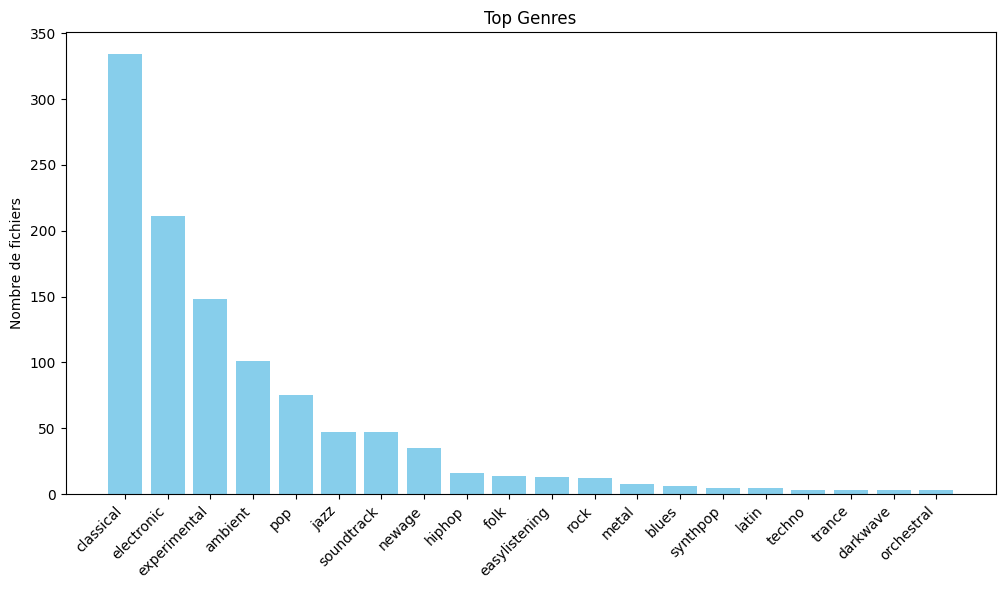

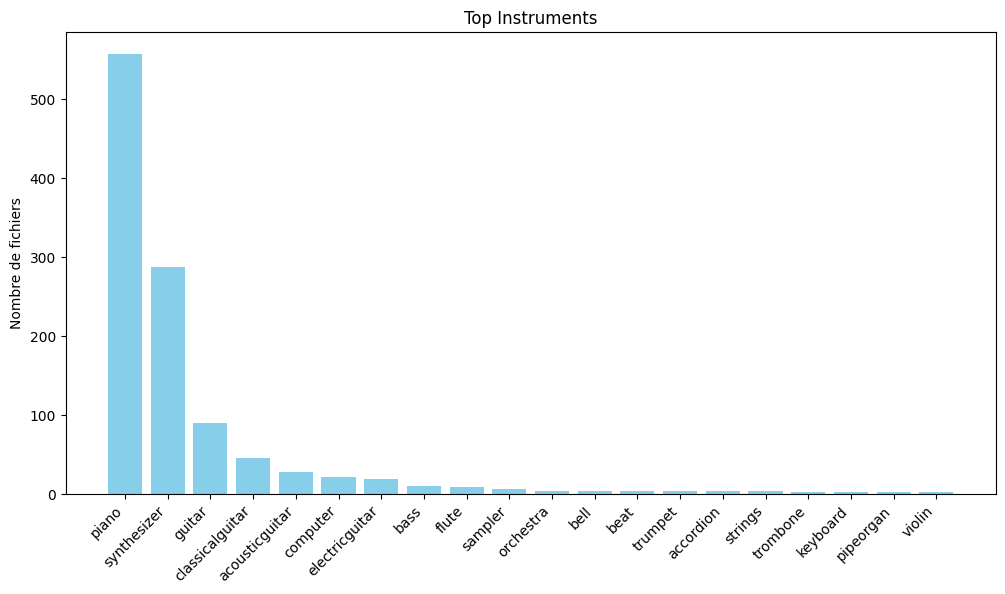

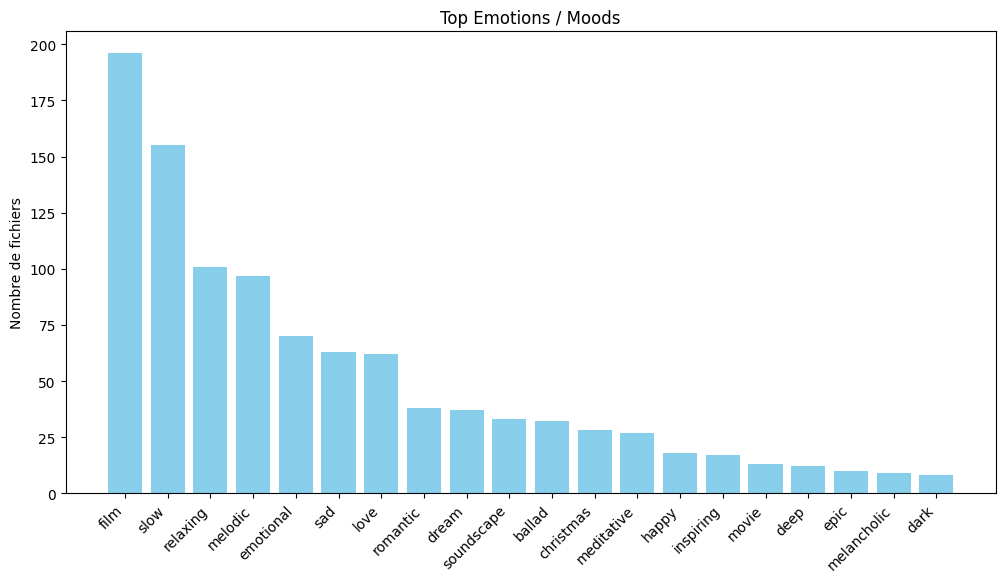

In [33]:
import matplotlib.pyplot as plt

def plot_top_tags(df, tag_column, count_column, title, top_n=20):
    top_df = df.head(top_n)
    plt.figure(figsize=(12,6))
    plt.bar(top_df[tag_column], top_df[count_column], color='skyblue')
    plt.xticks(rotation=45, ha='right')
    plt.title(title)
    plt.ylabel("Nombre de fichiers")
    plt.show()

plot_top_tags(df_genre, 'Genre', 'Count', "Top Genres")
plot_top_tags(df_instrument, 'Instrument', 'Count', "Top Instruments")
plot_top_tags(df_emotion, 'Emotion', 'Count', "Top Emotions / Moods")


In [1]:
import pandas as pd

# Charger CSV
csv_path = "muq_embedding_jamendo_multiclass.csv"
data = pd.read_csv(csv_path)

# Définir un seuil maximum pour les classes
max_per_class = 50

# Fonction pour limiter chaque classe
def balance_class(df, column, max_count):
    balanced_list = []
    for cls, group in df.groupby(column):
        if len(group) > max_count:
            group = group.sample(max_count, random_state=42)  # prendre un sous-échantillon
        balanced_list.append(group)
    return pd.concat(balanced_list).reset_index(drop=True)

# Appliquer pour les genres, instruments et émotions
data_balanced = balance_class(data, 'genre', max_per_class)
data_balanced = balance_class(data_balanced, 'instrument', max_per_class)
data_balanced = balance_class(data_balanced, 'emotion', max_per_class)

print("Shape du dataset équilibré :", data_balanced.shape)


Shape du dataset équilibré : (258, 1028)


In [6]:

class MusicDataset(Dataset):
    """Dataset pour les embeddings musicaux avec labels multiclasses"""
    
    def __init__(self, embeddings: np.ndarray, labels: Dict[str, np.ndarray]):
        self.embeddings = torch.FloatTensor(embeddings)
        self.labels = {key: torch.LongTensor(val) for key, val in labels.items()}
        
    def __len__(self):
        return len(self.embeddings)
    
    def __getitem__(self, idx):
        return {
            'embedding': self.embeddings[idx],
            'genre': self.labels['genre'][idx],
            'instrument': self.labels['instrument'][idx],
            'emotion': self.labels['emotion'][idx]
        }


In [7]:


class MultiTaskMusicClassifier(nn.Module):
    """
    Modèle de classification multi-tâches avec extraction d'embeddings
    """
    
    def __init__(self, input_dim: int, hidden_dims: List[int], 
                 num_genres: int, num_instruments: int, num_emotions: int,
                 dropout: float = 0.3):
        super().__init__()
        
        # Encodeur partagé
        layers = []
        prev_dim = input_dim
        for hidden_dim in hidden_dims:
            layers.extend([
                nn.Linear(prev_dim, hidden_dim),
                nn.BatchNorm1d(hidden_dim),
                nn.ReLU(),
                nn.Dropout(dropout)
            ])
            prev_dim = hidden_dim
        
        self.encoder = nn.Sequential(*layers)
        self.embedding_dim = hidden_dims[-1]
        
        # Têtes de classification
        self.genre_head = nn.Linear(self.embedding_dim, num_genres)
        self.instrument_head = nn.Linear(self.embedding_dim, num_instruments)
        self.emotion_head = nn.Linear(self.embedding_dim, num_emotions)
        
    def forward(self, x, return_embeddings=False):
        # Extraction des embeddings
        embeddings = self.encoder(x)
        
        if return_embeddings:
            return embeddings
        
        # Prédictions
        genre_logits = self.genre_head(embeddings)
        instrument_logits = self.instrument_head(embeddings)
        emotion_logits = self.emotion_head(embeddings)
        
        return {
            'genre': genre_logits,
            'instrument': instrument_logits,
            'emotion': emotion_logits,
            'embeddings': embeddings
        }
    
    def get_embeddings(self, x):
        """Extrait uniquement les embeddings de la dernière couche cachée"""
        with torch.no_grad():
            return self.encoder(x)

In [8]:


class MusicPlaylistGenerator:
    """
    Générateur de playlists basé sur la similarité des embeddings
    """
    
    def __init__(self, model: MultiTaskMusicClassifier, 
                 label_encoders: Dict[str, LabelEncoder],
                 track_ids: Optional[List] = None):
        self.model = model
        self.label_encoders = label_encoders
        self.track_ids = track_ids
        self.embeddings_cache = None
        self.nn_model = None
        
    def cache_embeddings(self, dataloader: DataLoader, device: str = None):
        """Cache tous les embeddings pour accélérer les recherches"""
        if device is None:
            device = next(self.model.parameters()).device
        
        self.model.eval()
        all_embeddings = []
        
        with torch.no_grad():
            for batch in dataloader:
                # Déplacer les données sur le bon device
                embeddings_input = batch['embedding'].to(device)
                embeddings = self.model.get_embeddings(embeddings_input)
                all_embeddings.append(embeddings.cpu().numpy())
        
        self.embeddings_cache = np.vstack(all_embeddings)
        
        # Construire le modèle de voisins les plus proches
        self.nn_model = NearestNeighbors(n_neighbors=50, metric='cosine')
        self.nn_model.fit(self.embeddings_cache)
        
    def create_playlist(self, seed_idx: int, playlist_size: int = 20,
                       diversity: float = 0.3) -> List[int]:
        """
        Crée une playlist à partir d'un morceau seed
        
        Args:
            seed_idx: Index du morceau de départ
            playlist_size: Nombre de morceaux dans la playlist
            diversity: 0=très similaire, 1=très diverse
        """
        if self.embeddings_cache is None:
            raise ValueError("Vous devez d'abord cacher les embeddings avec cache_embeddings()")
        
        playlist = [seed_idx]
        available_indices = set(range(len(self.embeddings_cache))) - {seed_idx}
        
        while len(playlist) < playlist_size and available_indices:
            # Trouver les voisins du dernier morceau ajouté
            current_embedding = self.embeddings_cache[playlist[-1]].reshape(1, -1)
            distances, indices = self.nn_model.kneighbors(current_embedding)
            
            # Filtrer les morceaux déjà dans la playlist
            candidates = [(i, d) for i, d in zip(indices[0], distances[0]) 
                         if i in available_indices]
            
            if not candidates:
                break
            
            # Sélection avec diversité
            if np.random.random() < diversity:
                # Sélection aléatoire parmi les top candidats
                top_k = min(10, len(candidates))
                selected_idx = candidates[np.random.randint(0, top_k)][0]
            else:
                # Sélection du plus proche
                selected_idx = candidates[0][0]
            
            playlist.append(selected_idx)
            available_indices.remove(selected_idx)
        
        return playlist
    
    def get_playlist_info(self, playlist_indices: List[int], 
                         data: pd.DataFrame) -> pd.DataFrame:
        """
        Récupère les informations détaillées d'une playlist
        
        Args:
            playlist_indices: Liste des indices des morceaux
            data: DataFrame original avec toutes les métadonnées
        """
        playlist_data = data.iloc[playlist_indices].copy()
        playlist_data['playlist_position'] = range(1, len(playlist_indices) + 1)
        
        # Réorganiser les colonnes
        info_cols = ['playlist_position', 'filename', 'genre', 'instrument', 'emotion']
        other_cols = [col for col in playlist_data.columns if col not in info_cols]
        
        return playlist_data[info_cols]
    
    def analyze_playlist_diversity(self, playlist_indices: List[int]) -> Dict:
        """
        Analyse la diversité d'une playlist
        """
        if self.embeddings_cache is None:
            raise ValueError("Les embeddings doivent être cachés d'abord")
        
        playlist_embeddings = self.embeddings_cache[playlist_indices]
        
        # Calculer les distances moyennes
        from scipy.spatial.distance import pdist
        distances = pdist(playlist_embeddings, metric='cosine')
        
        return {
            'mean_distance': np.mean(distances),
            'std_distance': np.std(distances),
            'min_distance': np.min(distances),
            'max_distance': np.max(distances),
            'median_distance': np.median(distances)
        }
    
    def visualize_embeddings(self, dataloader: DataLoader, 
                           color_by: str = 'genre',
                           n_samples: int = 1000,
                           device: str = None):
        """
        Visualise les embeddings en 2D avec t-SNE
        """
        if self.embeddings_cache is None:
            self.cache_embeddings(dataloader, device)
        
        # Sous-échantillonner si nécessaire
        if len(self.embeddings_cache) > n_samples:
            indices = np.random.choice(len(self.embeddings_cache), n_samples, replace=False)
            embeddings_subset = self.embeddings_cache[indices]
        else:
            indices = np.arange(len(self.embeddings_cache))
            embeddings_subset = self.embeddings_cache
        
        # t-SNE
        print("Calcul de t-SNE...")
        tsne = TSNE(n_components=2, random_state=42, perplexity=30)
        embeddings_2d = tsne.fit_transform(embeddings_subset)
        
        # Récupérer les labels
        all_labels = []
        for batch in dataloader:
            all_labels.append(batch[color_by].numpy())
        all_labels = np.concatenate(all_labels)[indices]
        
        # Visualisation
        plt.figure(figsize=(12, 8))
        scatter = plt.scatter(embeddings_2d[:, 0], embeddings_2d[:, 1], 
                            c=all_labels, cmap='tab20', alpha=0.6, s=20)
        plt.colorbar(scatter, label=color_by)
        plt.title(f'Visualisation t-SNE des embeddings (coloré par {color_by})')
        plt.xlabel('t-SNE dimension 1')
        plt.ylabel('t-SNE dimension 2')
        plt.tight_layout()
        
        return embeddings_2d, all_labels

In [9]:
class MusicTrainer:
    """Entraîneur pour le modèle multi-tâches"""
    
    def __init__(self, model: MultiTaskMusicClassifier, 
                 device: str = 'cuda' if torch.cuda.is_available() else 'cpu'):
        self.model = model.to(device)
        self.device = device
        
    def train_epoch(self, dataloader: DataLoader, optimizer, 
                   task_weights: Dict[str, float] = None):
        if task_weights is None:
            task_weights = {'genre': 0.8, 'instrument': 0.1, 'emotion': 0.1}
        
        self.model.train()
        total_loss = 0
        losses = {'genre': 0, 'instrument': 0, 'emotion': 0}
        
        for batch in dataloader:
            embeddings = batch['embedding'].to(self.device)
            
            # Forward pass
            outputs = self.model(embeddings)
            
            # Calcul des pertes
            loss_genre = F.cross_entropy(outputs['genre'], 
                                        batch['genre'].to(self.device))
            loss_instrument = F.cross_entropy(outputs['instrument'], 
                                             batch['instrument'].to(self.device))
            loss_emotion = F.cross_entropy(outputs['emotion'], 
                                          batch['emotion'].to(self.device))
            
            # Perte totale pondérée
            loss = (task_weights['genre'] * loss_genre + 
                   task_weights['instrument'] * loss_instrument + 
                   task_weights['emotion'] * loss_emotion)
            
            # Backward pass
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            
            # Accumulation des pertes
            total_loss += loss.item()
            losses['genre'] += loss_genre.item()
            losses['instrument'] += loss_instrument.item()
            losses['emotion'] += loss_emotion.item()
        
        n_batches = len(dataloader)
        return {
            'total': total_loss / n_batches,
            'genre': losses['genre'] / n_batches,
            'instrument': losses['instrument'] / n_batches,
            'emotion': losses['emotion'] / n_batches
        }
    
    def evaluate(self, dataloader: DataLoader):
        self.model.eval()
        correct = {'genre': 0, 'instrument': 0, 'emotion': 0}
        total = 0
        
        with torch.no_grad():
            for batch in dataloader:
                embeddings = batch['embedding'].to(self.device)
                outputs = self.model(embeddings)
                
                for task in ['genre', 'instrument', 'emotion']:
                    preds = outputs[task].argmax(dim=1)
                    correct[task] += (preds == batch[task].to(self.device)).sum().item()
                
                total += len(embeddings)
        
        return {task: correct[task] / total for task in correct}

/home/waarab/torchtest/lib/python3.12/site-packages/torch/cuda/__init__.py:129: UserWarning: CUDA initialization: CUDA unknown error - this may be due to an incorrectly set up environment, e.g. changing env variable CUDA_VISIBLE_DEVICES after program start. Setting the available devices to be zero. (Triggered internally at ../c10/cuda/CUDAFunctions.cpp:108.)
  return torch._C._cuda_getDeviceCount() > 0


In [10]:
# Fonction principale d'utilisation
def prepare_data(csv_path: str, embedding_column: str = 'embedding'):
    """
    Prépare les données à partir du CSV
    
    Args:
        csv_path: Chemin vers le CSV
        embedding_column: Nom de la colonne contenant les embeddings
                         (si c'est une seule colonne avec un vecteur)
    """
    data = pd.read_csv(csv_path)
    
    print(f"Colonnes du CSV: {data.columns.tolist()}")
    print(f"Premières lignes:\n{data.head()}")
    
    # Cas 1: Les embeddings sont dans une seule colonne (format string ou liste)
    if embedding_column in data.columns:
        print(f"Extraction des embeddings depuis la colonne '{embedding_column}'")
        embeddings_raw = data[embedding_column].values
        
        # Parser les embeddings
        embeddings_list = []
        for emb in embeddings_raw:
            if isinstance(emb, str):
                # Supprimer les crochets et parser
                emb = emb.strip('[]').replace('\n', ' ')
                emb_values = [float(x) for x in emb.split() if x]
                embeddings_list.append(emb_values)
            elif isinstance(emb, (list, np.ndarray)):
                embeddings_list.append(emb)
            else:
                raise ValueError(f"Format d'embedding non reconnu: {type(emb)}")
        
        embeddings = np.array(embeddings_list, dtype=np.float32)
    
    # Cas 2: Les embeddings sont répartis sur plusieurs colonnes numériques
    else:
        print("Recherche des colonnes d'embeddings...")
        # Identifier les colonnes numériques qui ne sont pas des labels
        exclude_cols = ['genre', 'instrument', 'emotion', 'track_id', 'Unnamed: 0']
        embedding_columns = [col for col in data.columns 
                           if col not in exclude_cols]
        
        if not embedding_columns:
            raise ValueError("Aucune colonne d'embedding trouvée. "
                           "Spécifiez le nom de la colonne avec embedding_column=")
        
        print(f"Colonnes d'embeddings détectées: {len(embedding_columns)} colonnes")
        
        # Extraire et convertir
        embeddings = data[embedding_columns].values
        
        # Gérer les types non-numériques
        if embeddings.dtype == object:
            # Convertir chaque cellule en float
            embeddings_list = []
            for row in embeddings:
                parsed_row = []
                for val in row:
                    try:
                        parsed_row.append(float(val))
                    except (ValueError, TypeError):
                        # Valeur manquante ou invalide
                        parsed_row.append(0.0)
                embeddings_list.append(parsed_row)
            embeddings = np.array(embeddings_list, dtype=np.float32)
        else:
            embeddings = embeddings.astype(np.float32)
    
    print(f"Shape des embeddings: {embeddings.shape}")
    print(f"Dtype: {embeddings.dtype}")
    
    # Encoder les labels
    label_encoders = {}
    labels = {}
    
    for task in ['genre', 'instrument', 'emotion']:
        le = LabelEncoder()
        labels[task] = le.fit_transform(data[task].values)
        label_encoders[task] = le
    
    # Split train/test
    indices = np.arange(len(embeddings))
    train_idx, test_idx = train_test_split(indices, test_size=0.2, random_state=42)
    
    train_embeddings = embeddings[train_idx]
    test_embeddings = embeddings[test_idx]
    train_labels = {k: v[train_idx] for k, v in labels.items()}
    test_labels = {k: v[test_idx] for k, v in labels.items()}
    
    # Récupérer les track IDs si disponibles
    track_ids = data['track_id'].values if 'track_id' in data.columns else None
    
    return {
        'train': (train_embeddings, train_labels),
        'test': (test_embeddings, test_labels),
        'label_encoders': label_encoders,
        'track_ids': track_ids,
        'num_classes': {
            'genre': len(label_encoders['genre'].classes_),
            'instrument': len(label_encoders['instrument'].classes_),
            'emotion': len(label_encoders['emotion'].classes_)
        }
    }


In [11]:
# 1. Charger et préparer les données
csv_path = "muq_embedding_jamendo_multiclass.csv"
data_dict = prepare_data(csv_path)

# Charger aussi le DataFrame complet pour les infos
full_data = pd.read_csv(csv_path)

# 2. Créer les datasets et dataloaders
train_dataset = MusicDataset(*data_dict['train'])
test_dataset = MusicDataset(*data_dict['test'])

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=32)

# 3. Initialiser le modèle
input_dim = data_dict['train'][0].shape[1]
model = MultiTaskMusicClassifier(
    input_dim=input_dim,
    hidden_dims=[512, 256, 128],
    num_genres=data_dict['num_classes']['genre'],
    num_instruments=data_dict['num_classes']['instrument'],
    num_emotions=data_dict['num_classes']['emotion']
)

Colonnes du CSV: ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9', '10', '11', '12', '13', '14', '15', '16', '17', '18', '19', '20', '21', '22', '23', '24', '25', '26', '27', '28', '29', '30', '31', '32', '33', '34', '35', '36', '37', '38', '39', '40', '41', '42', '43', '44', '45', '46', '47', '48', '49', '50', '51', '52', '53', '54', '55', '56', '57', '58', '59', '60', '61', '62', '63', '64', '65', '66', '67', '68', '69', '70', '71', '72', '73', '74', '75', '76', '77', '78', '79', '80', '81', '82', '83', '84', '85', '86', '87', '88', '89', '90', '91', '92', '93', '94', '95', '96', '97', '98', '99', '100', '101', '102', '103', '104', '105', '106', '107', '108', '109', '110', '111', '112', '113', '114', '115', '116', '117', '118', '119', '120', '121', '122', '123', '124', '125', '126', '127', '128', '129', '130', '131', '132', '133', '134', '135', '136', '137', '138', '139', '140', '141', '142', '143', '144', '145', '146', '147', '148', '149', '150', '151', '152', '153', '154', '155', 

In [12]:
# 4. Entraîner le modèle
trainer = MusicTrainer(model)
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

print("Entraînement du modèle...")
for epoch in range(50):
    train_losses = trainer.train_epoch(train_loader, optimizer)
    test_acc = trainer.evaluate(test_loader)
    
    print(f"Epoch {epoch+1}")
    print(f"  Train Loss: {train_losses['total']:.4f}")
    print(f"  Test Acc - Genre: {test_acc['genre']:.3f}, "
          f"Instrument: {test_acc['instrument']:.3f}, "
          f"Emotion: {test_acc['emotion']:.3f}")

Entraînement du modèle...
Epoch 1
  Train Loss: 2.2342
  Test Acc - Genre: 0.692, Instrument: 0.692, Emotion: 0.281
Epoch 2
  Train Loss: 1.2465
  Test Acc - Genre: 0.787, Instrument: 0.729, Emotion: 0.430
Epoch 3
  Train Loss: 0.9099
  Test Acc - Genre: 0.837, Instrument: 0.719, Emotion: 0.489
Epoch 4
  Train Loss: 0.7366
  Test Acc - Genre: 0.851, Instrument: 0.724, Emotion: 0.525
Epoch 5
  Train Loss: 0.6395
  Test Acc - Genre: 0.860, Instrument: 0.751, Emotion: 0.543
Epoch 6
  Train Loss: 0.5648
  Test Acc - Genre: 0.882, Instrument: 0.783, Emotion: 0.579
Epoch 7
  Train Loss: 0.5233
  Test Acc - Genre: 0.891, Instrument: 0.778, Emotion: 0.552
Epoch 8
  Train Loss: 0.4627
  Test Acc - Genre: 0.923, Instrument: 0.792, Emotion: 0.566
Epoch 9
  Train Loss: 0.4057
  Test Acc - Genre: 0.923, Instrument: 0.805, Emotion: 0.593
Epoch 10
  Train Loss: 0.3599
  Test Acc - Genre: 0.928, Instrument: 0.805, Emotion: 0.593
Epoch 11
  Train Loss: 0.3439
  Test Acc - Genre: 0.941, Instrument: 0.82

In [13]:
# 5. Créer le générateur de playlists
playlist_gen = MusicPlaylistGenerator(
    model=model,
    label_encoders=data_dict['label_encoders'],
    track_ids=data_dict['track_ids']
)


In [14]:
# 6. Cacher les embeddings
print("\nCaching des embeddings...")
full_dataset = MusicDataset(
    np.vstack([data_dict['train'][0], data_dict['test'][0]]),
    {k: np.concatenate([data_dict['train'][1][k], data_dict['test'][1][k]]) 
     for k in data_dict['train'][1]}
)
full_loader = DataLoader(full_dataset, batch_size=64)

# Détecter le device
device = 'cuda' if torch.cuda.is_available() else 'cpu'
playlist_gen.cache_embeddings(full_loader, device=device)

# 7. Créer plusieurs playlists avec différents seeds
print("\n" + "="*60)
print("GÉNÉRATION DE PLAYLISTS")
print("="*60)

for seed_idx in [0, 50, 100]:
    print(f"\n--- Playlist à partir du morceau {seed_idx} ---")
    
    # Info du seed
    seed_info = full_data.iloc[seed_idx]
    print(f"Seed: {seed_info['filename']}")
    print(f"  Genre: {seed_info['genre']}, "
          f"Instrument: {seed_info['instrument']}, "
          f"Emotion: {seed_info['emotion']}")
    
    # Créer la playlist
    playlist = playlist_gen.create_playlist(seed_idx, playlist_size=10, diversity=0.2)
    
    # Afficher les infos
    playlist_info = playlist_gen.get_playlist_info(playlist, full_data)
    print("\nPlaylist générée:")
    print(playlist_info.to_string(index=False))
    
    # Analyser la diversité
    diversity_stats = playlist_gen.analyze_playlist_diversity(playlist)
    print(f"\nDiversité de la playlist:")
    print(f"  Distance moyenne: {diversity_stats['mean_distance']:.4f}")
    print(f"  Écart-type: {diversity_stats['std_distance']:.4f}")
    print(f"  Min/Max: {diversity_stats['min_distance']:.4f} / "
          f"{diversity_stats['max_distance']:.4f}")


Caching des embeddings...

GÉNÉRATION DE PLAYLISTS

--- Playlist à partir du morceau 0 ---
Seed: 13/14013.low.mp3
  Genre: classical, Instrument: piano, Emotion: relaxing

Playlist générée:
 playlist_position           filename         genre      instrument      emotion
                 1   13/14013.low.mp3     classical           piano     relaxing
                 2 95/1009595.low.mp3     classical           piano        drama
                 3 39/1129939.low.mp3 easylistening     synthesizer motivational
                 4 80/1418980.low.mp3    soundtrack        computer        movie
                 5 85/1277185.low.mp3  experimental     synthesizer         slow
                 6 21/1204821.low.mp3          rock          guitar  melancholic
                 7 19/1121819.low.mp3       ambient     synthesizer   soundscape
                 8 92/1135792.low.mp3    electronic     synthesizer         deep
                 9 12/1028912.low.mp3     classical           piano          sad

In [15]:
# 8. Visualiser les embeddings
print("\n" + "="*60)
print("VISUALISATION DES EMBEDDINGS")
print("="*60)

playlist_gen.cache_embeddings(test_loader, device=device)

for color_by in ['genre', 'instrument', 'emotion']:
    print(f"\nVisualisation par {color_by}...")
    embeddings_2d, labels = playlist_gen.visualize_embeddings(
        test_loader, color_by=color_by, n_samples=500, device=device
    )
    plt.savefig(f'embeddings_tsne_{color_by}.png', dpi=300, bbox_inches='tight')
    print(f"  Sauvegardé: embeddings_tsne_{color_by}.png")
    plt.close()

print("\n" + "="*60)
print("TERMINÉ!")
print("="*60)

# 9. Sauvegarder le modèle
torch.save({
    'model_state_dict': model.state_dict(),
    'label_encoders': data_dict['label_encoders'],
    'input_dim': input_dim,
    'num_classes': data_dict['num_classes']
}, 'music_classifier_model.pth')
print("\nModèle sauvegardé dans 'music_classifier_model.pth'")


VISUALISATION DES EMBEDDINGS

Visualisation par genre...
Calcul de t-SNE...
  Sauvegardé: embeddings_tsne_genre.png

Visualisation par instrument...
Calcul de t-SNE...
  Sauvegardé: embeddings_tsne_instrument.png

Visualisation par emotion...
Calcul de t-SNE...
  Sauvegardé: embeddings_tsne_emotion.png

TERMINÉ!

Modèle sauvegardé dans 'music_classifier_model.pth'
